In [1]:
import helpy
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option('display.max_rows', 10)
pd.set_option('display.max_columns', 10)

In [2]:
analysis_df = helpy.get_analysis_df(.12, 100)

In [3]:
helpy.predict_residuals(analysis_df)

In [4]:
rf, pred = helpy.create_random_forest(analysis_df)

MAE:  12.394
RMSE: 15.540
R²:   0.247


In [5]:
rf, pred = helpy.create_random_forest(analysis_df, usage=False)

MAE:  12.312
RMSE: 15.446
R²:   0.256


In [6]:
best_rf, best_pred = helpy.create_random_forest(analysis_df, usage=False, movement=False, movement_residuals=True)

MAE:  12.183
RMSE: 15.343
R²:   0.266


In [7]:
rf, pred = helpy.create_random_forest(analysis_df, usage=False, fip=False)

MAE:  13.101
RMSE: 16.692
R²:   0.131


In [8]:
rf, pred = helpy.create_random_forest(analysis_df, usage=False, movement=False)

MAE:  12.343
RMSE: 15.430
R²:   0.257


In [9]:
rf, pred = helpy.create_random_forest(analysis_df, usage=False, velo=False)

MAE:  12.904
RMSE: 15.857
R²:   0.216


In [10]:
gam, pred = helpy.create_gam(analysis_df, usage=False, movement=False)

MAE:  12.318
RMSE: 15.332
R²:   0.267


In [11]:
baseline_gam, baseline_pred = helpy.create_gam(analysis_df, velo=False, movement=False, usage=False)

MAE:  12.795
RMSE: 15.704
R²:   0.231


In [12]:
analysis_df['baseline_pred_fip-'] = baseline_pred
analysis_df['best_pred_fip-'] = best_pred
analysis_df['fip-_diff_best_baseline'] = analysis_df['best_pred_fip-'] - analysis_df['baseline_pred_fip-']

In [13]:
results_df = analysis_df[['PlayerName', 'Season', 'FIP-', 'next_FIP-', 'baseline_pred_fip-', 'best_pred_fip-', 'fip-_diff_best_baseline', 'led_to_breakout']].copy()

In [32]:
results_df

,PlayerName,Season,FIP-,next_FIP-,baseline_pred_fip-,best_pred_fip-,fip-_diff_best_baseline,led_to_breakout
626,A.J. Burnett,2007,96.892057,78.991438,101.045473,90.888156,-10.157317,True
94,A.J. Burnett,2008,78.991438,94.480027,89.544890,88.209537,-1.335353,False
472,A.J. Burnett,2009,94.480027,111.454956,98.709782,95.787503,-2.922279,False
2389,A.J. Burnett,2010,111.454956,113.449929,106.949792,100.977194,-5.972598,False
2670,A.J. Burnett,2011,113.449929,93.177799,107.399998,99.188496,-8.211503,True
1682,A.J. Burnett,2012,93.177799,76.141763,97.402193,92.961536,-4.440657,True
1626,A.J. Burnett,2013,76.141763,109.588119,86.941239,91.411124,4.469886,False
2241,A.J. Burnett,2014,109.588119,87.998545,106.591797,99.020667,-7.571130,True
2343,A.J. Griffin,2013,116.436674,130.730591,107.953782,114.181396,6.227615,False
3521,Aaron Civale,2021,114.279639,84.753358,107.587887,104.572207,-3.015680,True


In [ ]:
results_df.sort_values('fip-_diff_best_baseline')[analysis_df['led_to_breakout']]

/tmp/ipykernel_23740/1433115961.py:1: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  results_df.sort_values('fip-_diff_best_baseline')[analysis_df['led_to_breakout']]


,PlayerName,Season,FIP-,next_FIP-,baseline_pred_fip-,best_pred_fip-,fip-_diff_best_baseline,led_to_breakout
2558,Carlos Rodón,2018,115.181181,59.684307,107.769990,92.456532,-15.313458,True
2568,Sonny Gray,2016,112.533528,88.967353,107.186388,92.699985,-14.486403,True
2814,Brad Peacock,2014,131.999153,70.627944,110.773110,96.416088,-14.357021,True
2612,Nathan Eovaldi,2016,112.491482,87.454371,107.176715,93.619373,-13.557342,True
2434,Danny Duffy,2015,112.026956,91.626529,107.071896,93.570005,-13.501891,True
...,...,...,...,...,...,...,...,...
3075,Tarik Skubal,2022,75.540358,59.581220,86.376994,89.594749,3.217755,True
1705,Kyle Hendricks,2018,93.994294,81.223425,98.222163,101.671415,3.449252,True
2901,Cristopher Sánchez,2024,72.279005,60.798144,83.585953,87.278799,3.692846,True
2896,Kevin Gausman,2021,73.683561,59.721516,84.728105,88.540491,3.812385,True


In [15]:
results_df.sort_values('fip-_diff_best_baseline')[analysis_df['PlayerName'] == 'Danny Duffy']

/tmp/ipykernel_23740/1736665584.py:1: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  results_df.sort_values('fip-_diff_best_baseline')[analysis_df['PlayerName'] == 'Danny Duffy']


,PlayerName,Season,FIP-,next_FIP-,baseline_pred_fip-,best_pred_fip-,fip-_diff_best_baseline,led_to_breakout
2434,Danny Duffy,2015,112.026956,91.626529,107.071896,93.570005,-13.501891,True
1816,Danny Duffy,2016,91.626529,80.177667,95.888967,85.771190,-10.117777,True
2656,Danny Duffy,2011,119.813971,102.216498,107.771937,99.356301,-8.415636,False
2425,Danny Duffy,2018,112.768728,106.293937,107.240878,100.828148,-6.412731,False
2115,Danny Duffy,2014,102.216498,112.026956,104.700167,99.710606,-4.989562,False
1663,Danny Duffy,2017,80.177667,112.768728,90.452758,94.894099,4.441341,False


In [16]:
top_1_perc = results_df.nsmallest(int(len(results_df) * 0.01), "fip-_diff_best_baseline")
top_5_perc = results_df.nsmallest(int(len(results_df) * 0.05), "fip-_diff_best_baseline")
top_10_perc = results_df.nsmallest(int(len(results_df) * 0.10), "fip-_diff_best_baseline")
top_25_perc = results_df.nsmallest(int(len(results_df) * 0.25), "fip-_diff_best_baseline")
top_50_perc = results_df.nsmallest(int(len(results_df) * 0.50), "fip-_diff_best_baseline")
top_75_perc = results_df.nsmallest(int(len(results_df) * 0.75), "fip-_diff_best_baseline")

In [17]:
print(results_df['led_to_breakout'].mean())
print(top_1_perc['led_to_breakout'].mean())
print(top_5_perc['led_to_breakout'].mean())
print(top_10_perc['led_to_breakout'].mean())
print(top_25_perc['led_to_breakout'].mean())
print(top_50_perc['led_to_breakout'].mean())
print(top_75_perc['led_to_breakout'].mean())

0.1711229946524064
0.8888888888888888
0.7096774193548387
0.6256684491978609
0.41755888650963596
0.3037433155080214
0.2225392296718973


In [18]:
df_2026 = helpy.get_year_df(2026)

In [19]:
df_2026

,PlayerName,Season,FIP-,ERA-,pivFA,...,pb_c_SI,pb_c_SL,pb_c_KC,pb_c_FC,pb_c_FS
2852,Jacob Misiorowski,2026,51.656283,43.435056,100.481248,...,NaN,53.310038,NaN,52.786862,NaN
2857,Cristopher Sánchez,2026,64.734308,67.255665,NaN,...,57.445728,54.672026,NaN,NaN,NaN
2859,Cam Schlittler,2026,60.425855,47.050507,98.022272,...,49.152783,41.377456,NaN,53.764641,NaN
2864,Chris Sale,2026,55.093629,51.409369,96.188106,...,60.382172,56.371195,NaN,NaN,NaN
2871,Jesús Luzardo,2026,64.195018,65.922214,96.889342,...,59.534787,45.821880,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...
3619,Spencer Arrighetti,2026,132.112838,120.737065,92.396777,...,48.352585,48.859652,NaN,55.298982,NaN
3627,Jeffrey Springs,2026,137.073867,137.865821,91.479949,...,NaN,55.233727,NaN,39.519045,NaN
3628,Eric Lauer,2026,141.090998,125.793461,91.016198,...,NaN,54.382827,NaN,51.939978,NaN
3636,Miles Mikolas,2026,134.777778,136.198055,93.277404,...,59.746018,58.830424,NaN,NaN,NaN


In [20]:
helpy.predict_residuals(df_2026)
df_2026['next_FIP-'] = 0
X, X_train, X_test, y_train, y_test = helpy.get_train_test_split(df_2026, usage=False, movement=False, movement_residuals=True)
X_baseline, X_train_baseline, X_test_baseline, y_train, y_test = helpy.get_train_test_split(df_2026, usage=False, movement=False, velo=False)

In [21]:
X_test

,pivFA,pivFC,pivSI,pivCH,pivSL,...,FC_Z_residual,SI_Z_residual,CH_Z_residual,SL_Z_residual,CU_Z_residual
2852,100.481248,95.228536,0.000000,92.589181,90.979257,...,-1.443209,0.000000,1.683953,-1.692083,0.091585
2857,0.000000,0.000000,95.074113,87.013050,86.272302,...,0.000000,-2.750148,-2.655693,-2.840388,0.000000
2859,98.022272,94.584637,97.843589,0.000000,89.669736,...,0.468497,0.642509,0.000000,1.438337,-1.271504
2864,96.188106,0.000000,95.550963,88.495937,79.756504,...,0.000000,-3.959001,-2.112953,-2.632040,0.000000
2871,96.889342,0.000000,95.771576,86.051741,86.118075,...,0.000000,-1.909805,-1.218352,-1.132975,-1.855079
...,...,...,...,...,...,...,...,...,...,...,...
3619,92.396777,87.731440,92.166538,84.247303,80.177690,...,1.445804,0.161229,-0.555920,0.997280,2.343611
3627,91.479949,87.265907,0.000000,79.651331,82.814103,...,0.782142,0.000000,0.006749,0.534700,0.000000
3628,91.016198,87.265430,0.000000,84.555409,82.498849,...,0.445194,0.000000,1.150983,1.123016,1.413127
3636,93.277404,0.000000,92.871304,85.627401,86.813537,...,0.000000,0.574234,-1.540936,2.151761,-1.657422


In [22]:
pred_2026 = best_rf.predict(X_test)
baseline_pred_2026 = baseline_gam.predict(X_test_baseline)

In [23]:
df_2026['baseline_pred_fip-'] = baseline_pred_2026
df_2026['best_pred_fip-'] = pred_2026
df_2026['fip-_diff_best_baseline'] = df_2026['best_pred_fip-'] - df_2026['baseline_pred_fip-']

In [24]:
results_df_2026 = df_2026[['PlayerName', 'Season', 'FIP-', 'next_FIP-', 'baseline_pred_fip-', 'best_pred_fip-', 'fip-_diff_best_baseline']].copy()

In [25]:
results_df_2026.sort_values('fip-_diff_best_baseline')

,PlayerName,Season,FIP-,next_FIP-,baseline_pred_fip-,best_pred_fip-,fip-_diff_best_baseline
3609,Nick Lodolo,2026,130.539648,0,110.151062,94.137747,-16.013315
3423,Matthew Liberatore,2026,111.694187,0,106.999888,93.504416,-13.495472
3396,Anthony Kay,2026,112.916386,0,107.275323,94.053091,-13.222232
3226,Bubba Chandler,2026,100.690360,0,103.936574,93.008088,-10.928486
3556,Tyler Phillips,2026,110.596111,0,106.779341,96.037478,-10.741862
...,...,...,...,...,...,...,...
3035,Kevin Gausman,2026,89.768514,0,94.281646,99.546342,5.264696
2964,Ranger Suarez,2026,76.507746,0,87.287710,94.930554,7.642845
2857,Cristopher Sánchez,2026,64.734308,0,79.185689,87.191802,8.006113
2859,Cam Schlittler,2026,60.425855,0,78.320711,86.600547,8.279835


In [26]:
results_df_2026['fip-_diff_best_baseline'].sum()

np.float64(-524.5581926406588)

In [27]:
from sklearn.metrics import roc_auc_score
from sklearn.metrics import average_precision_score

y = results_df['led_to_breakout']
score = -results_df['fip-_diff_best_baseline']

auc = roc_auc_score(y, score)
print(auc)
ap = average_precision_score(y, score)
print(ap)

0.8245423387096774
0.5262997889641757


In [28]:
percentiles = [0.05, 0.10, 0.15, 0.20, 0.25, 0.50]

for p in percentiles:
    k = int(len(y) * p)
    top = y.iloc[np.argsort(-score)[:k]]

    precision = top.mean()
    lift = precision / y.mean()

    print(p, precision, lift)

0.05 0.7096774193548387 4.147177419354839
0.1 0.6256684491978609 3.65625
0.15 0.525 3.0679687500000004
0.2 0.45454545454545453 2.65625
0.25 0.41755888650963596 2.4401097430406855
0.5 0.3037433155080214 1.7750000000000004


In [29]:
percentiles, fip_lift = helpy.lift_curve(
    results_df["led_to_breakout"], results_df["fip-_diff_best_baseline"]
)

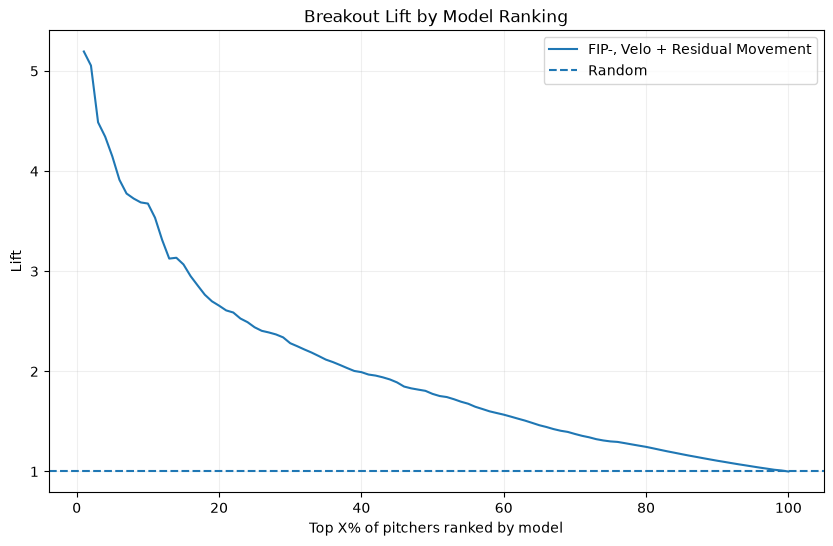

In [30]:
plt.figure(figsize=(10, 6))

plt.plot(percentiles * 100, fip_lift, label="FIP-, Velo + Residual Movement")

plt.axhline(1, linestyle="--", label="Random")

plt.xlabel("Top X% of pitchers ranked by model")
plt.ylabel("Lift")
plt.title("Breakout Lift by Model Ranking")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

In [31]:
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)